# RAC Diffusion Validation — Submission-Strengthening Notebook

This notebook is the **clean, submission-facing continuation** of `diffusers_v2`.
It deliberately avoids re-running the old exploratory sweeps unless necessary.

## What this adds

1. **Fast held-out validation** using the existing 64-example test split (no re-sampling).
2. **Checkpointed correctors** so corrected samples can be evaluated directly.
3. **Paired teacher-fidelity metrics**:
   - pixel MSE,
   - LPIPS.
4. **Distribution-level support** against real CIFAR-10:
   - KID (primary supportive distributional metric),
   - FID (secondary; interpret cautiously at small sample count).
5. **Paired bootstrap confidence intervals** for the practical claim:
   DDIM-50 + tiny corrector vs DDIM-500.
6. **Qualitative matched-sample grid**.
7. **Reproducibility manifest** and CSV/LaTeX exports.

### Scientific interpretation

The main RAC theory is about approximation to a fixed reference map. Therefore
teacher-fidelity metrics remain primary. KID/FID are included to check that the
practical result is not obviously a pixel-MSE-only artifact.

This FAST version avoids all new diffusion generation so it can run today. It does not remove the small-test-set limitation.

## 0. Optional dependencies

Run the next cell once if these packages are missing.

`torch-fidelity` is used by TorchMetrics for Inception features.
`lpips` is used for per-sample perceptual distance.

In [1]:
# Uncomment if needed:
# %pip install -U lpips torchmetrics torch-fidelity torchvision scipy pandas matplotlib diffusers

In [2]:
import os
import json
import math
import time
import copy
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

from diffusers import DDPMPipeline, DDIMScheduler

try:
    import torchvision
    from torchvision.datasets import CIFAR10
    from torchvision import transforms
except Exception as e:
    raise RuntimeError(
        "torchvision is required. Install it with: pip install torchvision"
    ) from e

device = "cuda" if torch.cuda.is_available() else "cpu"

PROJECT_DIR = Path(".")
DATA_DIR = PROJECT_DIR / "ddim_residual_data_512"
OUT_DIR = PROJECT_DIR / "top_tier_validation"
CKPT_DIR = OUT_DIR / "checkpoints"
EVAL_DIR = OUT_DIR / "eval_tensors"

for d in [OUT_DIR, CKPT_DIR, EVAL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

MODEL_ID = "google/ddpm-cifar10-32"

SEED = 20260927
N_EVAL = 256          # use 512 if runtime allows
GEN_BATCH = 16        # increase to 32 if VRAM allows
N_REAL_FOR_KID_FID = 2048

print("device:", device)
print("data dir:", DATA_DIR.resolve())
print("output dir:", OUT_DIR.resolve())

C:\Users\Public\Anaconda3\envs\tabpfn_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu
data dir: D:\PhD EMP\Paper Writting\STEP_COMPLEXITY\ddim_residual_data_512
output dir: D:\PhD EMP\Paper Writting\STEP_COMPLEXITY\top_tier_validation


## 1. Deterministic setup and reproducibility manifest

In [3]:
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Reproducibility-first settings.
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

set_seed(SEED)

manifest = {
    "seed": SEED,
    "n_eval": N_EVAL,
    "gen_batch": GEN_BATCH,
    "model_id": MODEL_ID,
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "device": device,
    "cuda_version": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}

try:
    import diffusers
    manifest["diffusers"] = diffusers.__version__
except Exception:
    manifest["diffusers"] = None

print(json.dumps(manifest, indent=2))

{
  "seed": 20260927,
  "n_eval": 256,
  "gen_batch": 16,
  "model_id": "google/ddpm-cifar10-32",
  "python": "3.11.16",
  "pytorch": "2.14.0+cpu",
  "torchvision": "0.29.0+cpu",
  "device": "cpu",
  "cuda_version": null,
  "gpu": null,
  "diffusers": "0.40.0"
}


## 2. Load the diffusion model and define deterministic DDIM

The reference remains the fixed deterministic DDIM-1000 map used in the paper.

In [4]:
pipe = DDPMPipeline.from_pretrained(MODEL_ID)
unet = pipe.unet.to(device)
unet.eval()

@torch.no_grad()
def ddim_map(z, num_steps):
    scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
    scheduler.set_timesteps(
        num_inference_steps=num_steps,
        device=device
    )

    x = z.to(device)

    for t in scheduler.timesteps:
        model_input = scheduler.scale_model_input(x, t)
        noise_pred = unet(model_input, t).sample
        x = scheduler.step(
            model_output=noise_pred,
            timestep=t,
            sample=x,
            eta=0.0
        ).prev_sample

    return x

@torch.no_grad()
def ddim_map_batched(z, num_steps, batch_size=16):
    chunks = []
    n_batches = math.ceil(len(z) / batch_size)

    for bi, start in enumerate(range(0, len(z), batch_size), start=1):
        xb = z[start:start + batch_size]
        print(f"steps={num_steps:4d} | batch {bi:3d}/{n_batches:3d}")
        chunks.append(
            ddim_map(xb, num_steps=num_steps).detach().cpu()
        )

    return torch.cat(chunks, dim=0)

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.
Loading pipeline components...: 100%|██████████| 2/2 [00:00<00:00, 10.53it/s]


## 3. Load the original 512-example RAC dataset

This preserves the exact train/validation split used in the main experiment:
384 / 64 / 64.

In [5]:
required = [
    DATA_DIR / "z.pt",
    DATA_DIR / "teacher_1000.pt",
    DATA_DIR / "baseline_50.pt",
    DATA_DIR / "baseline_500.pt",
]

missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Missing existing RAC tensors:\n" + "\n".join(missing) +
        "\nPlace this notebook in the same project folder as ddim_residual_data_512."
    )

z_512 = torch.load(DATA_DIR / "z.pt", map_location="cpu")
teacher_512 = torch.load(DATA_DIR / "teacher_1000.pt", map_location="cpu")
baseline_50_512 = torch.load(DATA_DIR / "baseline_50.pt", map_location="cpu")
baseline_500_512 = torch.load(DATA_DIR / "baseline_500.pt", map_location="cpu")

N_TRAIN = 384
N_VAL = 64
TRAIN_END = N_TRAIN
VAL_END = N_TRAIN + N_VAL

z_train = z_512[:TRAIN_END]
z_val = z_512[TRAIN_END:VAL_END]
z_test = z_512[VAL_END:]

residuals = {
    50: teacher_512 - baseline_50_512,
    500: teacher_512 - baseline_500_512,
}

res_train = {C: R[:TRAIN_END] for C, R in residuals.items()}
res_val = {C: R[TRAIN_END:VAL_END] for C, R in residuals.items()}
res_test = {C: R[VAL_END:] for C, R in residuals.items()}

print("train/val/test:", len(z_train), len(z_val), len(z_test))
for C in [50, 500]:
    print(
        f"C={C:3d} | residual RMS="
        f"{residuals[C].pow(2).mean().sqrt().item():.6f}"
    )

train/val/test: 384 64 64
C= 50 | residual RMS=0.464478
C=500 | residual RMS=0.272936


## 4. Final corrector implementation

Unlike the exploratory notebook, this trainer returns and saves the fitted model
and its train-only residual scale. This is required to generate corrected outputs
on genuinely unseen latents.

In [6]:
class CorrectionCNN(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, width, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(width, width, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(width, width, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(width, 3, 3, padding=1),
        )

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_final_corrector(
    C,
    width,
    max_epochs=1000,
    batch_size=32,
    lr=1e-3,
    patience=40,
    min_delta=1e-5,
    seed=0,
):
    set_seed(seed)

    model = CorrectionCNN(width).to(device)

    train_rms = torch.sqrt((res_train[C] ** 2).mean()).item()
    y_train = res_train[C] / train_rms

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        TensorDataset(z_train, y_train),
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    best_val_nmse = float("inf")
    best_state = None
    best_epoch = None
    bad_epochs = 0

    for epoch in range(1, max_epochs + 1):
        model.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad(set_to_none=True)
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            pred_val = model(z_val.to(device)).cpu() * train_rms
            val_mse = ((pred_val - res_val[C]) ** 2).mean().item()
            val_energy = (res_val[C] ** 2).mean().item()
            val_nmse = val_mse / val_energy

        if val_nmse < best_val_nmse - min_delta:
            best_val_nmse = val_nmse
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        pred_test = model(z_test.to(device)).cpu() * train_rms

    test_mse = ((pred_test - res_test[C]) ** 2).mean().item()
    test_energy = (res_test[C] ** 2).mean().item()
    test_nmse = test_mse / test_energy

    payload = {
        "C": C,
        "width": width,
        "params": count_params(model),
        "train_rms": train_rms,
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_nmse": best_val_nmse,
        "test_nmse": test_nmse,
        "state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
    }

    path = CKPT_DIR / f"corrector_C{C}_w{width}_seed{seed}.pt"
    torch.save(payload, path)

    return model, payload

@torch.no_grad()
def predict_residual(model, z, train_rms, batch_size=64):
    model.eval()
    outs = []
    for start in range(0, len(z), batch_size):
        xb = z[start:start + batch_size].to(device)
        outs.append((model(xb).cpu() * train_rms))
    return torch.cat(outs, dim=0)

## 5. Train the submission-facing correctors

We keep the set intentionally small:

- **C=50, width=1**: the 78-parameter practical system.
- **C=50, width=32**: stronger correction capacity.
- **C=500, width=32**: comparison showing the high-budget residual remains harder.

These are not used to tune on the new evaluation latents.

In [7]:
FINAL_CONFIGS = [
    (50, 1),
    (50, 32),
    (500, 32),
]

models = {}
train_rows = []

for C, width in FINAL_CONFIGS:
    print("=" * 70)
    print(f"Training C={C}, width={width}")
    model, payload = train_final_corrector(
        C=C,
        width=width,
        max_epochs=1000,
        batch_size=32,
        lr=1e-3,
        patience=40,
        seed=0,
    )
    models[(C, width)] = model

    train_rows.append({
        k: payload[k]
        for k in [
            "C", "width", "params", "seed",
            "best_epoch", "best_val_nmse", "test_nmse"
        ]
    })

df_training = pd.DataFrame(train_rows)
display(df_training)
df_training.to_csv(OUT_DIR / "final_corrector_training.csv", index=False)

Training C=50, width=1
Training C=50, width=32
Training C=500, width=32


,C,width,params,seed,best_epoch,best_val_nmse,test_nmse
0,50,1,78,0,291,0.341495,0.337864
1,50,32,20259,0,75,0.311454,0.322834
2,500,32,20259,0,75,0.484846,0.551075


## 6. FAST submission mode: reuse the existing held-out test split

To finish the submission sprint today, we **do not regenerate DDIM-1000 / DDIM-500 / DDIM-50 samples**.
We reuse the exact 64 held-out examples already present in `ddim_residual_data_512`.

This is scientifically valid for:
- pixel MSE to the fixed DDIM-1000 reference,
- LPIPS to the fixed reference,
- paired bootstrap comparisons,
- matched qualitative figures.

It **does not solve the small-test-set limitation**. The paper must therefore state that these perceptual checks
are performed on the existing 64-example held-out split. A larger independent evaluation can be run later if desired.

In [8]:
# Existing held-out split: indices 448:512
z_eval = z_test.clone()

teacher_eval = teacher_512[VAL_END:].clone()
ddim50_eval = baseline_50_512[VAL_END:].clone()
ddim500_eval = baseline_500_512[VAL_END:].clone()

N_EVAL = len(z_eval)

print("FAST held-out evaluation:")
print("N_EVAL:", N_EVAL)
print("z_eval:", z_eval.shape)
print("teacher_eval:", teacher_eval.shape)
print("ddim50_eval:", ddim50_eval.shape)
print("ddim500_eval:", ddim500_eval.shape)

FAST held-out evaluation:
N_EVAL: 64
z_eval: torch.Size([64, 3, 32, 32])
teacher_eval: torch.Size([64, 3, 32, 32])
ddim50_eval: torch.Size([64, 3, 32, 32])
ddim500_eval: torch.Size([64, 3, 32, 32])


## 7. Produce corrected outputs on independent latents

In [9]:
payloads = {}
for C, width in FINAL_CONFIGS:
    payloads[(C, width)] = torch.load(
        CKPT_DIR / f"corrector_C{C}_w{width}_seed0.pt",
        map_location="cpu"
    )

corr50_w1 = predict_residual(
    models[(50, 1)],
    z_eval,
    payloads[(50, 1)]["train_rms"],
)

corr50_w32 = predict_residual(
    models[(50, 32)],
    z_eval,
    payloads[(50, 32)]["train_rms"],
)

corr500_w32 = predict_residual(
    models[(500, 32)],
    z_eval,
    payloads[(500, 32)]["train_rms"],
)

systems_raw = {
    "DDIM-50": ddim50_eval,
    "DDIM-50 + w1 corrector": ddim50_eval + corr50_w1,
    "DDIM-50 + w32 corrector": ddim50_eval + corr50_w32,
    "DDIM-500": ddim500_eval,
    "DDIM-500 + w32 corrector": ddim500_eval + corr500_w32,
    "DDIM-1000 reference": teacher_eval,
}

# For perceptual/distributional metrics only.
systems_clipped = {
    k: v.clamp(-1, 1)
    for k, v in systems_raw.items()
}

print("systems:", list(systems_raw))

systems: ['DDIM-50', 'DDIM-50 + w1 corrector', 'DDIM-50 + w32 corrector', 'DDIM-500', 'DDIM-500 + w32 corrector', 'DDIM-1000 reference']


## 8. Independent teacher-fidelity results

We report both raw and clipped pixel MSE. The **raw MSE** is directly aligned with
the paper's reference-map objective.

In [10]:
def per_sample_mse(x, y):
    return ((x - y) ** 2).flatten(1).mean(dim=1)

teacher_rows = []
per_sample_mse_dict = {}

for name, x in systems_raw.items():
    if name == "DDIM-1000 reference":
        continue

    raw = per_sample_mse(x, teacher_eval)
    clipped = per_sample_mse(x.clamp(-1, 1), teacher_eval.clamp(-1, 1))

    per_sample_mse_dict[name] = raw

    teacher_rows.append({
        "system": name,
        "N": len(raw),
        "MSE_to_teacher_raw": raw.mean().item(),
        "MSE_to_teacher_clipped": clipped.mean().item(),
        "SE_raw": raw.std(unbiased=True).item() / math.sqrt(len(raw)),
    })

df_teacher = pd.DataFrame(teacher_rows).sort_values("MSE_to_teacher_raw")
display(df_teacher)
df_teacher.to_csv(OUT_DIR / "independent_teacher_fidelity.csv", index=False)

,system,N,MSE_to_teacher_raw,MSE_to_teacher_clipped,SE_raw
4,DDIM-500 + w32 corrector,64,0.039005,0.037804,0.007054
2,DDIM-50 + w32 corrector,64,0.064090,0.059582,0.007174
1,DDIM-50 + w1 corrector,64,0.067073,0.062866,0.007160
3,DDIM-500,64,0.070779,0.070779,0.009740
0,DDIM-50,64,0.198522,0.198522,0.020865


## 9. Paired bootstrap confidence intervals

The headline comparison is paired because all systems use exactly the same latent
inputs. A negative difference means the first system is better.

In [11]:
def paired_bootstrap_mean_diff(a, b, n_boot=10000, seed=12345):
    a = torch.as_tensor(a, dtype=torch.float64)
    b = torch.as_tensor(b, dtype=torch.float64)
    assert a.shape == b.shape

    d = (a - b).cpu().numpy()
    rng = np.random.default_rng(seed)
    n = len(d)

    idx = rng.integers(0, n, size=(n_boot, n))
    boot = d[idx].mean(axis=1)

    return {
        "mean_diff": float(d.mean()),
        "ci95_low": float(np.quantile(boot, 0.025)),
        "ci95_high": float(np.quantile(boot, 0.975)),
        "fraction_diff_lt_0": float((boot < 0).mean()),
    }

comparisons = [
    ("DDIM-50 + w1 corrector", "DDIM-500"),
    ("DDIM-50 + w32 corrector", "DDIM-500"),
]

boot_rows = []

for a_name, b_name in comparisons:
    out = paired_bootstrap_mean_diff(
        per_sample_mse_dict[a_name],
        per_sample_mse_dict[b_name],
    )
    boot_rows.append({
        "metric": "MSE_to_teacher_raw",
        "system_A": a_name,
        "system_B": b_name,
        **out,
    })

df_boot_mse = pd.DataFrame(boot_rows)
display(df_boot_mse)
df_boot_mse.to_csv(OUT_DIR / "bootstrap_mse_differences.csv", index=False)

,metric,system_A,system_B,mean_diff,ci95_low,ci95_high,fraction_diff_lt_0
0,MSE_to_teacher_raw,DDIM-50 + w1 corrector,DDIM-500,-0.003706,-0.015154,0.007592,0.7396
1,MSE_to_teacher_raw,DDIM-50 + w32 corrector,DDIM-500,-0.006689,-0.017834,0.004467,0.8849


## 10. LPIPS to the DDIM-1000 reference

This checks whether the correction advantage also appears in a learned perceptual
feature space rather than only in pixel MSE.

In [12]:
try:
    import lpips
except ImportError as e:
    raise RuntimeError(
        "Install LPIPS first: pip install lpips"
    ) from e

lpips_model = lpips.LPIPS(net="alex").to(device)
lpips_model.eval()

@torch.no_grad()
def per_sample_lpips(x, y, batch_size=64):
    vals = []

    for start in range(0, len(x), batch_size):
        xb = x[start:start + batch_size].to(device).clamp(-1, 1)
        yb = y[start:start + batch_size].to(device).clamp(-1, 1)

        d = lpips_model(xb, yb)
        vals.append(d.flatten().detach().cpu())

    return torch.cat(vals)

lpips_dict = {}
lpips_rows = []

for name, x in systems_clipped.items():
    if name == "DDIM-1000 reference":
        continue

    vals = per_sample_lpips(x, teacher_eval)
    lpips_dict[name] = vals

    lpips_rows.append({
        "system": name,
        "N": len(vals),
        "LPIPS_to_teacher": vals.mean().item(),
        "SE": vals.std(unbiased=True).item() / math.sqrt(len(vals)),
    })

df_lpips = pd.DataFrame(lpips_rows).sort_values("LPIPS_to_teacher")
display(df_lpips)
df_lpips.to_csv(OUT_DIR / "independent_lpips.csv", index=False)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


C:\Users\Public\Anaconda3\envs\tabpfn_env\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Public\Anaconda3\envs\tabpfn_env\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: C:\Users\Public\Anaconda3\envs\tabpfn_env\Lib\site-packages\lpips\weights\v0.1\alex.pth


,system,N,LPIPS_to_teacher,SE
4,DDIM-500 + w32 corrector,64,0.041088,0.005237
3,DDIM-500,64,0.056341,0.006968
2,DDIM-50 + w32 corrector,64,0.074312,0.006482
1,DDIM-50 + w1 corrector,64,0.081647,0.006102
0,DDIM-50,64,0.143156,0.012867


In [13]:
lpips_boot_rows = []

for a_name, b_name in comparisons:
    out = paired_bootstrap_mean_diff(
        lpips_dict[a_name],
        lpips_dict[b_name],
    )
    lpips_boot_rows.append({
        "metric": "LPIPS_to_teacher",
        "system_A": a_name,
        "system_B": b_name,
        **out,
    })

df_boot_lpips = pd.DataFrame(lpips_boot_rows)
display(df_boot_lpips)
df_boot_lpips.to_csv(
    OUT_DIR / "bootstrap_lpips_differences.csv",
    index=False
)

,metric,system_A,system_B,mean_diff,ci95_low,ci95_high,fraction_diff_lt_0
0,LPIPS_to_teacher,DDIM-50 + w1 corrector,DDIM-500,0.025306,0.012668,0.038259,0.0000
1,LPIPS_to_teacher,DDIM-50 + w32 corrector,DDIM-500,0.017971,0.005525,0.031240,0.0026


## 11. KID and FID against real CIFAR-10

**Interpretation rule for the paper:**
- KID is the preferred supportive distributional metric here.
- FID is reported descriptively, especially when `N_EVAL` is only 256.
- Neither replaces the paired teacher-fidelity analysis.

The real-image subset is deterministic and independent of model training.

In [15]:
from torchvision.datasets import CIFAR10
from torchvision import transforms

cifar_root = OUT_DIR / "cifar10_data"

cifar_test = CIFAR10(
    root=str(cifar_root),
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)

print("CIFAR-10 test size:", len(cifar_test))

CIFAR-10 test size: 10000


In [16]:
from torchmetrics.image.kid import KernelInceptionDistance

# ---------------------------------------------------------
# FAST distributional validation
# ---------------------------------------------------------

N_REAL_FAST = 256
FEATURE_BATCH = 64

systems_fast = {
    "DDIM-50": systems_clipped["DDIM-50"],
    "DDIM-50 + w1 corrector": systems_clipped["DDIM-50 + w1 corrector"],
    "DDIM-500": systems_clipped["DDIM-500"],
    "DDIM-1000 reference": systems_clipped["DDIM-1000 reference"],
}

rng = np.random.default_rng(SEED)

real_indices = rng.choice(
    len(cifar_test),
    size=N_REAL_FAST,
    replace=False
)

real_tensors = torch.stack(
    [cifar_test[int(i)][0] for i in real_indices],
    dim=0
)

def unit_float_to_uint8(x):
    return (x.clamp(0, 1) * 255).round().to(torch.uint8)

def minus1_1_to_uint8(x):
    x = (x.clamp(-1, 1) + 1) / 2
    return unit_float_to_uint8(x)

real_uint8 = unit_float_to_uint8(real_tensors)

kid = KernelInceptionDistance(
    subset_size=min(32, len(z_eval)),
    subsets=20,
    normalize=False,
    reset_real_features=False
).to(device)

print("Encoding real CIFAR images once...")

for start in range(0, len(real_uint8), FEATURE_BATCH):
    xb = real_uint8[start:start + FEATURE_BATCH].to(device)
    kid.update(xb, real=True)

print("Real features cached.")

dist_rows = []

for name, x in systems_fast.items():
    print("KID:", name)

    fake_uint8 = minus1_1_to_uint8(x)

    for start in range(0, len(fake_uint8), FEATURE_BATCH):
        xb = fake_uint8[start:start + FEATURE_BATCH].to(device)
        kid.update(xb, real=False)

    kid_mean, kid_std = kid.compute()

    dist_rows.append({
        "system": name,
        "N_fake": len(fake_uint8),
        "N_real": len(real_uint8),
        "KID_mean": float(kid_mean.cpu()),
        "KID_std": float(kid_std.cpu()),
    })

    kid.reset()

df_dist = pd.DataFrame(dist_rows).sort_values("KID_mean")

display(df_dist)

df_dist.to_csv(
    OUT_DIR / "distributional_metrics_FAST.csv",
    index=False
)

C:\Users\Public\Anaconda3\envs\tabpfn_env\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


Encoding real CIFAR images once...
Real features cached.
KID: DDIM-50
KID: DDIM-50 + w1 corrector
KID: DDIM-500
KID: DDIM-1000 reference


,system,N_fake,N_real,KID_mean,KID_std
2,DDIM-500,64,256,0.008635,0.006319
0,DDIM-50,64,256,0.015457,0.006080
3,DDIM-1000 reference,64,256,0.018694,0.008616
1,DDIM-50 + w1 corrector,64,256,0.044409,0.010582


## 12. Matched qualitative figure

Rows correspond to the **same latent inputs**, so visual differences are directly
comparable. This figure is diagnostic/supportive, not a replacement for metrics.

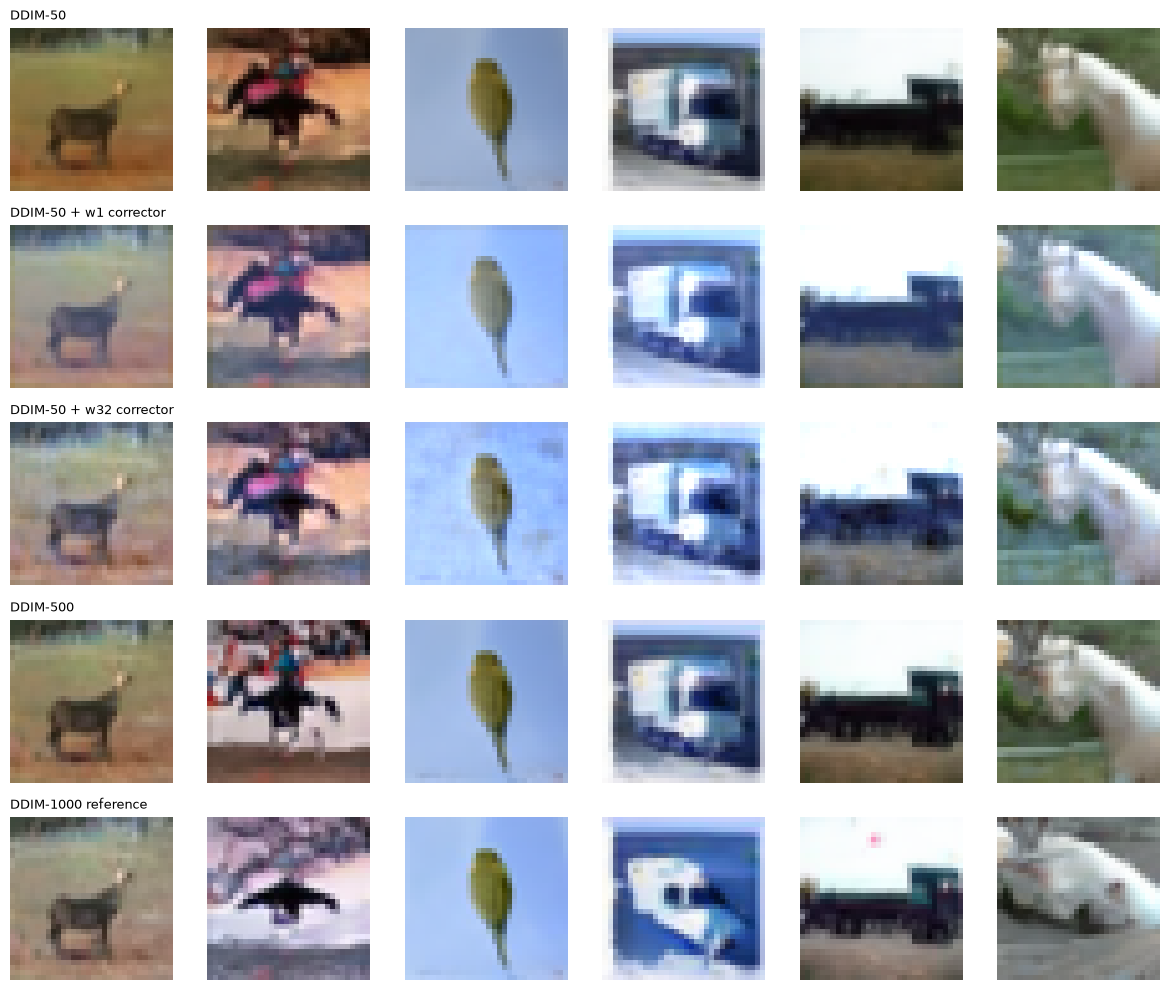

In [17]:
def to_display(x):
    return ((x.clamp(-1, 1) + 1.0) / 2.0).permute(1, 2, 0).numpy()

show_systems = [
    "DDIM-50",
    "DDIM-50 + w1 corrector",
    "DDIM-50 + w32 corrector",
    "DDIM-500",
    "DDIM-1000 reference",
]

N_SHOW = 6
fig, axes = plt.subplots(
    len(show_systems),
    N_SHOW,
    figsize=(2.0 * N_SHOW, 2.0 * len(show_systems)),
)

for r, name in enumerate(show_systems):
    for c in range(N_SHOW):
        axes[r, c].imshow(to_display(systems_clipped[name][c]))
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(name, loc="left", fontsize=9)

fig.tight_layout()
fig.savefig(
    OUT_DIR / "matched_samples.png",
    dpi=220,
    bbox_inches="tight",
)
plt.show()

## 13. Submission-facing summary plot

This plot should be interpreted together with the paired bootstrap table.

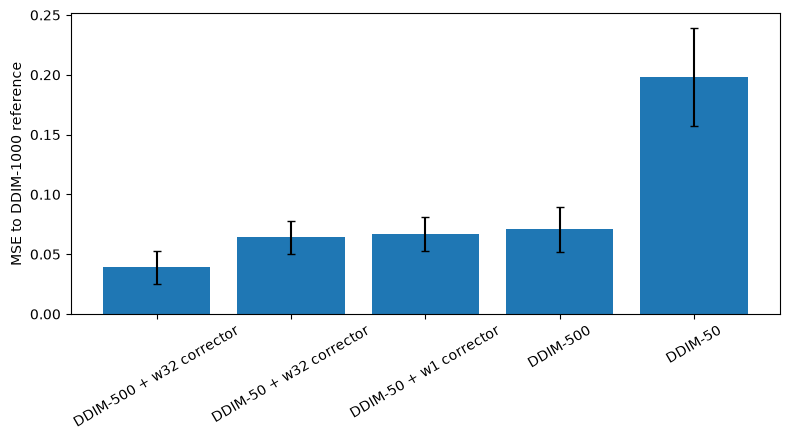

In [18]:
plot_df = df_teacher.copy()

fig, ax = plt.subplots(figsize=(8.0, 4.5))
ax.bar(
    plot_df["system"],
    plot_df["MSE_to_teacher_raw"],
    yerr=1.96 * plot_df["SE_raw"],
    capsize=3,
)
ax.set_ylabel("MSE to DDIM-1000 reference")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(
    OUT_DIR / "independent_eval_mse.png",
    dpi=220,
    bbox_inches="tight",
)
fig.savefig(
    OUT_DIR / "independent_eval_mse.pdf",
    bbox_inches="tight",
)
plt.show()

## 14. Reproducibility manifest and paper-ready exports

In [19]:
manifest.update({
    "train_size": N_TRAIN,
    "val_size": N_VAL,
    "original_test_size": len(z_test),
    "independent_eval_size": N_EVAL,
    "corrector_optimizer": "Adam",
    "corrector_lr": 1e-3,
    "corrector_batch_size": 32,
    "corrector_max_epochs": 1000,
    "corrector_patience": 40,
    "corrector_min_delta": 1e-5,
    "residual_normalization": "train RMS only",
    "reference": "deterministic DDIM-1000, eta=0",
    "evaluation_baselines": [50, 500],
})

with open(OUT_DIR / "reproducibility_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

paper_table = (
    df_teacher
    .merge(
        df_lpips[["system", "LPIPS_to_teacher"]],
        on="system",
        how="left",
    )
    .merge(
        df_dist[["system", "KID_mean", "KID_std"]],
        on="system",
        how="left",
    )
)

display(paper_table)

paper_table.to_csv(
    OUT_DIR / "paper_validation_table.csv",
    index=False
)

latex_text = paper_table.to_latex(
    index=False,
    float_format=lambda x: f"{x:.6f}",
)

with open(OUT_DIR / "paper_validation_table.tex", "w") as f:
    f.write(latex_text)

print("Saved outputs to:", OUT_DIR.resolve())

latex_text = paper_table.to_latex(
    index=False,
    float_format=lambda x: f"{x:.6f}",
)

with open(OUT_DIR / "paper_validation_table.tex", "w") as f:
    f.write(latex_text)

print("Saved outputs to:", OUT_DIR.resolve())
print("Main table:", (OUT_DIR / "paper_validation_table.csv").resolve())
print("LaTeX table:", (OUT_DIR / "paper_validation_table.tex").resolve())

,system,N,MSE_to_teacher_raw,MSE_to_teacher_clipped,SE_raw,LPIPS_to_teacher,KID_mean,KID_std
0,DDIM-500 + w32 corrector,64,0.039005,0.037804,0.007054,0.041088,NaN,NaN
1,DDIM-50 + w32 corrector,64,0.064090,0.059582,0.007174,0.074312,NaN,NaN
2,DDIM-50 + w1 corrector,64,0.067073,0.062866,0.007160,0.081647,0.044409,0.010582
3,DDIM-500,64,0.070779,0.070779,0.009740,0.056341,0.008635,0.006319
4,DDIM-50,64,0.198522,0.198522,0.020865,0.143156,0.015457,0.006080


Saved outputs to: D:\PhD EMP\Paper Writting\STEP_COMPLEXITY\top_tier_validation
Saved outputs to: D:\PhD EMP\Paper Writting\STEP_COMPLEXITY\top_tier_validation
Main table: D:\PhD EMP\Paper Writting\STEP_COMPLEXITY\top_tier_validation\paper_validation_table.csv
LaTeX table: D:\PhD EMP\Paper Writting\STEP_COMPLEXITY\top_tier_validation\paper_validation_table.tex


# Decision rules before inserting results into the paper

Use the new experiment to strengthen the manuscript **only according to the
observed results**.

### Strong outcome
If DDIM-50 + tiny corrector:
- beats or matches DDIM-500 in independent pixel MSE,
- has a paired bootstrap interval compatible with the claimed advantage,
- and does not materially worsen LPIPS/KID,

then the practical claim becomes substantially stronger.

### Mixed outcome
If pixel MSE improves but LPIPS/KID is unchanged within noise, report exactly
that: correction improves teacher-map fidelity without detectable degradation in
the auxiliary perceptual/distributional metrics.

### Negative outcome
If LPIPS/KID clearly deteriorates, do **not** hide it. The paper's central RAC
result can still stand, but the practical claim must remain explicitly about
fidelity to the fixed DDIM-1000 reference.

### FID caveat
With only 256 generated samples, FID is descriptive. KID and paired teacher
metrics should receive more weight. If time permits, rerun this notebook with
`N_EVAL=512`.